In [2]:
import pandas as pd

corpus = pd.read_csv("../data/corpus.csv")
corpus = corpus[corpus["remarque"].fillna("") != "exclure"]

X = corpus["titre"]
y = corpus["theme_final"]

print(len(corpus), "titres")
y.value_counts()

236 titres


theme_final
education    43
societe      42
sante        40
politique    39
economie     36
sport        36
Name: count, dtype: int64

Étape 2 : la baseline (TF-IDF sur les mots + régression logistique)

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

baseline = make_pipeline(
    TfidfVectorizer(lowercase=True),
    LogisticRegression(max_iter=1000)
)
baseline

Pipeline(steps=[('tfidfvectorizer', TfidfVectorizer()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [4]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, classification_report

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pred_base = cross_val_predict(baseline, X, y, cv=cv)

print("Macro-F1 baseline :", round(f1_score(y, pred_base, average="macro"), 3))
print(classification_report(y, pred_base))

Macro-F1 baseline : 0.593
              precision    recall  f1-score   support

    economie       0.50      0.31      0.38        36
   education       0.60      0.77      0.67        43
   politique       0.69      0.56      0.62        39
       sante       0.77      0.75      0.76        40
     societe       0.48      0.71      0.57        42
       sport       0.68      0.47      0.56        36

    accuracy                           0.61       236
   macro avg       0.62      0.60      0.59       236
weighted avg       0.62      0.61      0.60       236



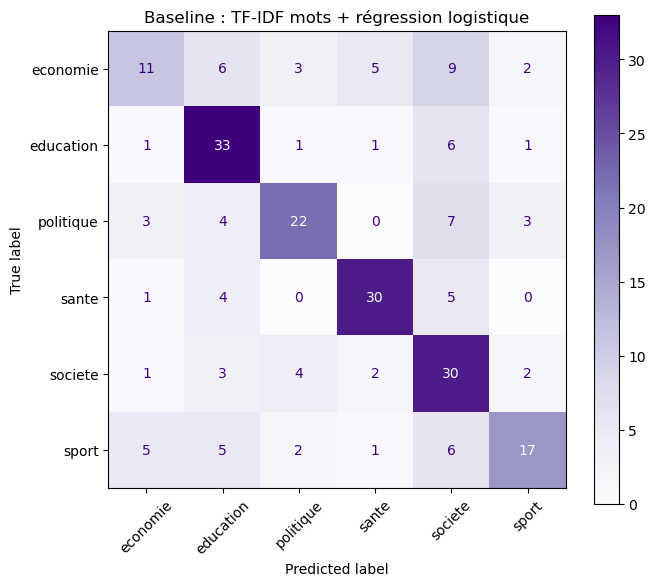

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y, pred_base, ax=ax, cmap="Purples", xticks_rotation=45)
ax.set_title("Baseline : TF-IDF mots + régression logistique")
plt.tight_layout()
plt.savefig("../resultats/matrice_confusion_baseline.png", dpi=150)
plt.show()

Étape 4 : approche 2 (TF-IDF caractères + régression logistique)

In [7]:
approche2 = make_pipeline(
    TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 5)),
    LogisticRegression(max_iter=1000)
)

pred_car = cross_val_predict(approche2, X, y, cv=cv)

print("Macro-F1 approche 2 :", round(f1_score(y, pred_car, average="macro"), 3))
print(classification_report(y, pred_car))

Macro-F1 approche 2 : 0.646
              precision    recall  f1-score   support

    economie       0.59      0.47      0.52        36
   education       0.66      0.88      0.75        43
   politique       0.78      0.64      0.70        39
       sante       0.78      0.72      0.75        40
     societe       0.56      0.79      0.65        42
       sport       0.67      0.39      0.49        36

    accuracy                           0.66       236
   macro avg       0.67      0.65      0.65       236
weighted avg       0.67      0.66      0.65       236



Étape 5 : le tableau comparatif, avec la stabilité des scores

In [9]:
from sklearn.model_selection import cross_val_score

score_base = cross_val_score(baseline, X, y, cv=cv, scoring="f1_macro")
score_car = cross_val_score(approche2, X, y, cv=cv, scoring="f1_macro")

comparaison = pd.DataFrame({
    "Approche": ["Baseline : TF-IDF mots + LR", "Approche 2 : TF-IDF caractères (2-5) + LR"],
    "Macro-F1 moyenne": [score_base.mean().round(3), score_car.mean().round(3)],
    "Écart-type": [score_base.std().round(3), score_car.std().round(3)],
    "Plis gagnés": [(score_base > score_car).sum(), (score_car > score_base).sum()],
})
comparaison.to_csv("../resultats/comparaison.csv", index=False)

print("Par pli, baseline :", score_base.round(3))
print("Par pli, approche 2 :", score_car.round(3))
comparaison

Par pli, baseline : [0.529 0.63  0.609 0.574 0.602]
Par pli, approche 2 : [0.518 0.674 0.693 0.689 0.643]


,Approche,Macro-F1 moyenne,Écart-type,Plis gagnés
0,Baseline : TF-IDF mots + LR,0.589,0.035,1
1,Approche 2 : TF-IDF caractères (2-5) + LR,0.643,0.065,4


## Test : l'approche 2 profite-t-elle des signes typographiques ?

L'exploration (`01b_exploration.ipynb`) a montré que 71 % des titres de La Nation finissent par « ... », contre 0 % à l'ADI. Le modèle sur les caractères peut s'en servir comme raccourci. On nettoie donc les titres, puis on refait la comparaison.

In [10]:
import re

def normaliser(titre):
    titre = titre.replace("’", "'").replace("\xa0", " ")
    titre = re.sub(r"\s*(\.\.\.|…)\s*$", "", titre)
    return titre.strip()

X_norm = X.apply(normaliser)

base_norm = cross_val_score(baseline, X_norm, y, cv=cv, scoring="f1_macro")
car_norm = cross_val_score(approche2, X_norm, y, cv=cv, scoring="f1_macro")

pd.DataFrame({
    "Titres": ["bruts", "nettoyés"],
    "Baseline (mots)": [score_base.mean().round(3), base_norm.mean().round(3)],
    "Approche 2 (caractères)": [score_car.mean().round(3), car_norm.mean().round(3)],
    "Plis gagnés par l'approche 2": [(score_car > score_base).sum(), (car_norm > base_norm).sum()],
})

,Titres,Baseline (mots),Approche 2 (caractères),Plis gagnés par l'approche 2
0,bruts,0.589,0.643,4
1,nettoyés,0.589,0.626,4


La baseline ne change pas : elle découpe en mots et ignore déjà la ponctuation. L'approche 2 perd 0,017 : environ un tiers de son avance venait des signes typographiques propres à La Nation. Mais elle reste meilleure (0,626 contre 0,589) et gagne toujours 4 plis sur 5 : l'essentiel de son avantage vient bien du découpage en caractères.

Étape 5 : la matrice de confusion de l’approche 2

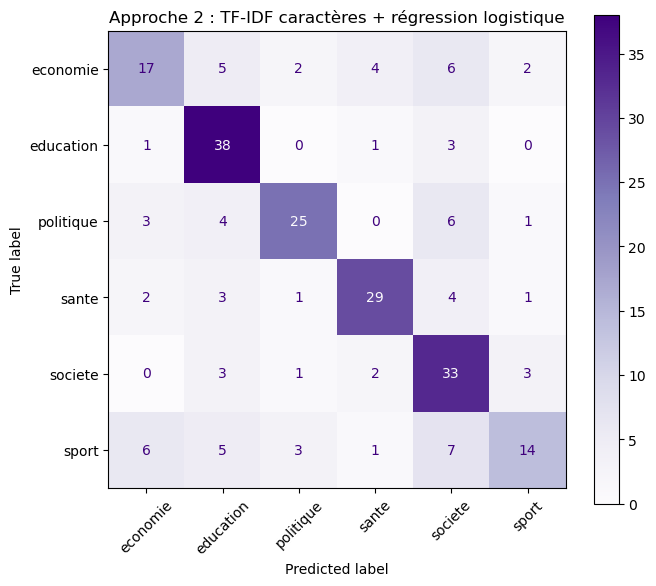

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y, pred_car, ax=ax, cmap="Purples", xticks_rotation=45)
ax.set_title("Approche 2 : TF-IDF caractères + régression logistique")
plt.tight_layout()
plt.savefig("../resultats/matrice_confusion_approche2.png", dpi=150)
plt.show()

Étape 6 : extraire les erreurs et vérifier le biais de source

In [12]:
corpus["predit"] = pred_car
corpus["erreur"] = corpus["theme_final"] != corpus["predit"]

print(corpus["erreur"].sum(), "erreurs sur", len(corpus))
print()
print("Taux d'erreur par source :")
print(corpus.groupby("source")["erreur"].mean().round(3))
print()

erreurs = corpus[corpus["erreur"]]
print("Vers quel thème partent les erreurs, selon la source :")
print(pd.crosstab(erreurs["source"], erreurs["predit"]))

erreurs[["id", "titre", "source", "theme_final", "predit", "remarque"]].to_csv("../resultats/erreurs_approche2.csv", index=False)
erreurs[["id", "titre", "source", "theme_final", "predit"]]

80 erreurs sur 236

Taux d'erreur par source :
source
ADI          0.343
La Nation    0.333
Name: erreur, dtype: float64

Vers quel thème partent les erreurs, selon la source :
predit     economie  education  politique  sante  societe  sport
source                                                          
ADI               8          5          6      6       16      6
La Nation         4         15          1      2       10      1


,id,titre,source,theme_final,predit
0,1,Ayla Hôtel abrite les travaux d'un atelier de ...,ADI,economie,politique
3,4,Journée de l’Afrique : Vladimir Poutine salue ...,La Nation,politique,societe
6,7,Football : Samuel Eto’o à Djibouti pour l’asse...,ADI,sport,education
8,9,2ème édition de la Conférence africaine des st...,La Nation,economie,societe
15,16,"Quatre géants, deux places en finale",La Nation,sport,societe
...,...,...,...,...,...
222,223,Le Parlement adopte le budget 2026 et une loi ...,ADI,politique,societe
223,224,"Dileita Mohamed Dileita, entre émotion et dévo...",ADI,politique,societe
229,230,Les FFDJ et la FDA organisent la 42e édition d...,ADI,sport,societe
230,231,Santé : la CNSS signe un partenariat pour déve...,ADI,sante,economie


In [13]:
choisis = [223, 1, 103, 115, 106, 217, 48, 133, 110, 71, 168, 179, 16, 26]
corpus[corpus["id"].isin(choisis)][["id", "titre", "source", "theme_final", "predit"]]

,id,titre,source,theme_final,predit
0,1,Ayla Hôtel abrite les travaux d'un atelier de ...,ADI,economie,politique
15,16,"Quatre géants, deux places en finale",La Nation,sport,societe
25,26,L’INSP prépare une offensive contre les gîtes ...,La Nation,sante,education
47,48,La zone franche internationale de Djibouti enr...,ADI,economie,societe
70,71,Célébration de la journée internationale de la...,ADI,societe,education
102,103,"Bakou, le ministre Dawaleh met en garde contre...",ADI,economie,politique
105,106,Yassin Souleiman Hassan élu vice-président de ...,ADI,sport,politique
109,110,Célébration de la Journée Internationale de l’...,La Nation,education,societe
114,115,Le Président Guelleh remet les prix aux lauréa...,ADI,societe,politique
132,133,Djibouti confie la gestion du port de Tadjoura...,ADI,economie,societe


## Étape 6 : analyse des erreurs (approche 2)

**80 erreurs sur 236 titres.** Taux d'erreur presque identique selon la source : ADI 34,3 %, La Nation 33,3 %.

**Biais de source partiel** : quand le modèle se trompe, il se rabat en partie sur le thème propre au journal d'origine.
- Erreurs de La Nation vers *education* (thème présent seulement chez La Nation) : 15 sur 33.
- Erreurs de l'ADI vers *societe* (thème présent seulement chez l'ADI) : 16 sur 47.

### 14 erreurs analysées, regroupées par cause

| id | Titre (début) | Vrai | Prédit | Cause |
|---|---|---|---|---|
| **1. Thèmes qui se chevauchent** | | | | |
| 223 | Le Parlement adopte le budget 2026 et une loi sur le patrimoine culturel | politique | societe | Deux sujets dans un titre : « patrimoine culturel » tire vers société. |
| 1 | Ayla Hôtel abrite… validation des textes juridiques… finances publiques | economie | politique | Vocabulaire juridique et institutionnel pour un sujet budgétaire. |
| 103 | Bakou, le ministre Dawaleh met en garde… changement climatique | economie | politique | Cas limite déjà repéré à l'annotation : l'étiquette elle-même est discutable. |
| **2. Le vocabulaire des acteurs l'emporte sur le sujet** | | | | |
| 115 | Le Président Guelleh remet les prix… concours de mémorisation du Saint Coran | societe | politique | « Président Guelleh » est un indice de politique plus fort que le sujet religieux. |
| 106 | Yassin Souleiman Hassan élu vice-président de la Fédération internationale des échecs | sport | politique | « Élu vice-président » sonne politique ; « échecs » est rare. |
| 217 | La Secrétaire d'État chargée des Sports reçoit le Comité exécutif du… | sport | politique | Titre protocolaire (« Secrétaire d'État », « reçoit ») et coupé. |
| **3. Biais de source (ADI vers société)** | | | | |
| 48 | La zone franche internationale de Djibouti enregistre une hausse de ses activités… | economie | societe | Titre clairement économique, au style ADI, envoyé vers le thème propre à l'ADI. |
| 133 | Djibouti confie la gestion du port de Tadjourah à un opérateur saoudien | economie | societe | Même phénomène : sujet portuaire et économique, classé en société. |
| **4. Formules partagées entre thèmes** | | | | |
| 110 | Célébration de la Journée Internationale de l'Enseignant… | education | societe | « Célébration de la journée internationale » est une formule typique des titres culturels. |
| 71 | Célébration de la journée internationale de la langue chinoise à Djibouti | societe | education | Cas miroir du précédent : « langue » tire vers l'éducation. |
| **5. Titres pauvres en indices** | | | | |
| 168 | la bande à Ahmed Salah s'imposait contre toute attente à Hiroshima | sport | sante | Titre coupé, sans mot de sport : seulement des noms propres et un lieu. |
| 179 | Deux médailles pour Djibouti au 3000 m steeple et au 10 000 m… | sport | economie | Les nombres ressemblent aux montants des titres économiques. |
| **6. Erreurs propres à l'approche 2** (la baseline avait juste) | | | | |
| 16 | Quatre géants, deux places en finale | sport | societe | En mots entiers, « finale » suffisait ; en morceaux de lettres, l'indice se dilue. |
| 26 | L'INSP prépare une offensive contre les gîtes larvaires | sante | education | « larvaires » était décisif en mot entier, moins en morceaux de lettres. |

### Ce qu'on retient
- La plupart des erreurs viennent de **titres ambigus ou pauvres en mots-clés**, pas d'un défaut du modèle.
- Le **style du journal** influence une partie des erreurs : c'est une limite du corpus (éducation seulement chez La Nation, société seulement chez l'ADI).
- Les n-grammes de caractères aident l'économie mais **affaiblissent le sport**, dont les titres reposent sur des noms propres et quelques mots-clés courts.

Étape 7 : modèle final pour la démonstration

In [14]:
import joblib

approche2.fit(X, y)
joblib.dump(approche2, "../modele.joblib")

exemples = [
    "Lancement d'une campagne de vaccination contre la rougeole à Tadjourah",
    "Les Requins de Djibouti s'imposent face au Kenya",
    "Le port de Doraleh enregistre une hausse de son trafic",
]
for titre, theme in zip(exemples, approche2.predict(exemples)):
    print(theme, "←", titre)

sante ← Lancement d'une campagne de vaccination contre la rougeole à Tadjourah
sport ← Les Requins de Djibouti s'imposent face au Kenya
economie ← Le port de Doraleh enregistre une hausse de son trafic
